# Drug–Target Interaction Prediction

## Notebook 02: Data Cleaning & Interaction Labeling

### Objective

This notebook prepares the raw ChEMBL bioactivity data for machine
learning.

The raw dataset may contain:
- Missing values
- Duplicate measurements
- Different activity types
- Different activity units
- Non-numeric activity values
- Multiple measurements for the same compound

Therefore, the data must be cleaned and standardized before feature
engineering and machine learning.

### Workflow

1. Load raw ChEMBL data
2. Inspect dataset structure
3. Select relevant columns
4. Handle missing values
5. Standardize activity measurements
6. Remove invalid records
7. Remove duplicates
8. Define interaction labels
9. Perform quality checks
10. Save processed dataset

In [ ]:
## 1. Import Libraries

# Import the Python libraries required for data loading, cleaning,
# numerical processing, and visualization.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load Raw ChEMBL Dataset

The raw activity dataset was generated in Notebook 01 using ChEMBL.

We load the original dataset without modifying it so that the raw data
remains reproducible.

In [ ]:
raw_path = "../data/raw/h1_receptor_activity.csv"

activity_df = pd.read_csv(raw_path)

print("Dataset loaded successfully.")
print("Shape:", activity_df.shape)

Dataset loaded successfully.
Shape: (6816, 47)


## 3. Initial Data Inspection

Before performing any cleaning, we inspect the dimensions, columns,
data types, and sample records of the raw dataset.

This provides a baseline for measuring how the dataset changes during
preprocessing.

In [ ]:
activity_df.head()

,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,bao_format,bao_label,canonical_smiles,data_validity_comment,data_validity_description,document_chembl_id,document_journal,document_year,ligand_efficiency,modality,molecule_chembl_id,molecule_pref_name,parent_molecule_chembl_id,pchembl_value,potential_duplicate,qudt_units,record_id,relation,src_id,standard_flag,standard_relation,standard_text_value,standard_type,standard_units,standard_upper_value,standard_value,target_chembl_id,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,NaN,NaN,72509,[],CHEMBL694561,Inhibition of [3H]- doxepine binding to histam...,B,NaN,NaN,BAO_0000201,BAO_0000357,single protein format,CP(=O)(O)C[C@@H](O)CN,NaN,NaN,CHEMBL1128747,J Med Chem,1995.0,NaN,NaN,CHEMBL113310,NaN,CHEMBL113310,NaN,0,http://qudt.org/vocab/unit#Percent,211386,=,1,1,=,NaN,Inhibition,%,NaN,22.0,CHEMBL231,Homo sapiens,Histamine H1 receptor,9606,NaN,NaN,Inhibition,%,UO_0000187,NaN,22.0
1,NaN,NaN,85576,[],CHEMBL694562,Inhibition of [3H]- doxepine binding to histam...,B,NaN,NaN,BAO_0000201,BAO_0000357,single protein format,NCCC[PH](=O)O,NaN,NaN,CHEMBL1128747,J Med Chem,1995.0,NaN,NaN,CHEMBL112203,NaN,CHEMBL112203,NaN,0,http://qudt.org/vocab/unit#Percent,211376,=,1,1,=,NaN,Inhibition,%,NaN,0.0,CHEMBL231,Homo sapiens,Histamine H1 receptor,9606,NaN,NaN,Inhibition,%,UO_0000187,NaN,0.0
2,NaN,NaN,100483,[],CHEMBL694561,Inhibition of [3H]- doxepine binding to histam...,B,NaN,NaN,BAO_0000201,BAO_0000357,single protein format,CP(=O)(O)CCCN,NaN,NaN,CHEMBL1128747,J Med Chem,1995.0,NaN,NaN,CHEMBL112710,NaN,CHEMBL112710,NaN,0,http://qudt.org/vocab/unit#Percent,211375,=,1,1,=,NaN,Inhibition,%,NaN,30.0,CHEMBL231,Homo sapiens,Histamine H1 receptor,9606,NaN,NaN,Inhibition,%,UO_0000187,NaN,30.0
3,NaN,NaN,110076,[],CHEMBL691619,In vitro binding affinity of compound against ...,B,NaN,NaN,BAO_0000192,BAO_0000357,single protein format,CN1CCN(C2=Nc3ccccc3Nc3sc(CO)cc32)CC1,NaN,NaN,CHEMBL1150510,Bioorg Med Chem Lett,1997.0,"{'bei': '25.03', 'le': '0.49', 'lle': '5.60', ...",NaN,CHEMBL100454,NaN,CHEMBL100454,8.22,0,http://www.openphacts.org/units/Nanomolar,189654,=,1,1,=,NaN,Ki,nM,NaN,6.0,CHEMBL231,Homo sapiens,Histamine H1 receptor,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,6.0
4,NaN,NaN,116755,[],CHEMBL691619,In vitro binding affinity of compound against ...,B,NaN,NaN,BAO_0000192,BAO_0000357,single protein format,Cc1cc2c(s1)Nc1ccccc1N=C2N1CCN(C)CC1,NaN,NaN,CHEMBL1150510,Bioorg Med Chem Lett,1997.0,"{'bei': '26.10', 'le': '0.51', 'lle': '4.71', ...",NaN,CHEMBL715,OLANZAPINE,CHEMBL715,8.15,0,http://www.openphacts.org/units/Nanomolar,189652,=,1,1,=,NaN,Ki,nM,NaN,7.0,CHEMBL231,Homo sapiens,Histamine H1 receptor,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,7.0


In [ ]:
activity_df.shape

(6816, 47)

In [ ]:
activity_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6816 entries, 0 to 6815
Data columns (total 47 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   action_type                560 non-null    object 
 1   activity_comment           3734 non-null   object 
 2   activity_id                6816 non-null   int64  
 3   activity_properties        6816 non-null   object 
 4   assay_chembl_id            6816 non-null   object 
 5   assay_description          6816 non-null   object 
 6   assay_type                 6816 non-null   object 
 7   assay_variant_accession    13 non-null     object 
 8   assay_variant_mutation     13 non-null     object 
 9   bao_endpoint               6816 non-null   object 
 10  bao_format                 6816 non-null   object 
 11  bao_label                  6816 non-null   object 
 12  canonical_smiles           6737 non-null   object 
 13  data_validity_comment      92 non-null     objec

## 4. Missing Value Analysis

ChEMBL activity records may contain missing values for fields such as
standard activity values and pChEMBL values.

We quantify missing values before deciding which records can be used
for downstream analysis.

In [ ]:
missing_summary = (
    activity_df[
        [
            "molecule_chembl_id",
            "target_chembl_id",
            "standard_type",
            "standard_value",
            "standard_units",
            "pchembl_value"
        ]
    ]
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_summary

pchembl_value         4804
standard_units        2118
standard_value        2109
molecule_chembl_id       0
target_chembl_id         0
standard_type            0
dtype: int64

## 5. Inspect pChEMBL Availability

pChEMBL is a standardized logarithmic representation of bioactivity
provided by ChEMBL for suitable activity measurements.

Because our raw dataset contains many different measurement types and
units, pChEMBL provides a more consistent numerical representation for
the initial machine-learning dataset.

We first determine how many records contain a valid pChEMBL value.

In [ ]:
print("Total records:", len(activity_df))

print(
    "Records with pChEMBL:",
    activity_df["pchembl_value"].notna().sum()
)

print(
    "Records without pChEMBL:",
    activity_df["pchembl_value"].isna().sum()
)

Total records: 6816
Records with pChEMBL: 2012
Records without pChEMBL: 4804


In [ ]:
activity_df["pchembl_value"].describe()

count    2012.000000
mean        6.827132
std         1.328865
min         4.000000
25%         5.720000
50%         6.825000
75%         7.900000
max        10.850000
Name: pchembl_value, dtype: float64

## 6. Filter Records with Valid pChEMBL Values

For the initial ML dataset, we retain records with a valid numerical
pChEMBL value.

Records without pChEMBL are retained in the raw dataset but excluded
from this initial standardized dataset because their activity values
cannot be directly represented using the same numerical scale.

This filtering step will be revisited if additional activity data is
required later.

In [ ]:
activity_clean = activity_df[
    activity_df["pchembl_value"].notna()
].copy()

print("Records before filtering:", len(activity_df))
print("Records after filtering:", len(activity_clean))

Records before filtering: 6816
Records after filtering: 2012


## 7. Convert pChEMBL to Numeric

The pChEMBL column is converted explicitly to a numerical data type.
Invalid values are converted to missing values and subsequently removed.

This ensures that the feature can be used by machine-learning
algorithms.

In [ ]:
activity_clean["pchembl_value"] = pd.to_numeric(
    activity_clean["pchembl_value"],
    errors="coerce"
)

activity_clean = activity_clean[
    activity_clean["pchembl_value"].notna()
].copy()

print("Valid pChEMBL records:", len(activity_clean))

Valid pChEMBL records: 2012


## 8. Validate pChEMBL Values

We inspect the distribution of pChEMBL values to identify potentially
invalid or extreme records.

Extremely large or unusual values may indicate data-entry issues,
unusual assay conditions, or records that require additional biological
inspection.

We do not remove outliers automatically. They are inspected first.

In [ ]:
activity_clean["pchembl_value"].describe()

count    2012.000000
mean        6.827132
std         1.328865
min         4.000000
25%         5.720000
50%         6.825000
75%         7.900000
max        10.850000
Name: pchembl_value, dtype: float64

In [ ]:
activity_clean[
    ["standard_type", "standard_value", "standard_units", "pchembl_value"]
].sort_values(
    "pchembl_value",
    ascending=False
).head(20)

,standard_type,standard_value,standard_units,pchembl_value
3646,IC50,0.0140,nM,10.85
1829,Ki,0.0490,nM,10.31
1905,Ki,0.0660,nM,10.18
3079,Kd,0.0870,nM,10.06
4847,Kd,0.1000,nM,10.00
4841,Kd,0.1318,nM,9.88
2347,Ki,0.1380,nM,9.86
4848,Kd,0.1585,nM,9.80
2373,Ki,0.1750,nM,9.76
2975,Ki,0.1778,nM,9.75


## 9. Bioactivity Types Represented by pChEMBL

After filtering for valid pChEMBL values, we examine which experimental
measurement types remain.

This allows us to verify that the standardized dataset contains
appropriate quantitative bioactivity measurements.

In [ ]:
activity_clean["standard_type"].value_counts()

standard_type
Ki      1374
IC50     255
AC50     207
Kd       158
EC50      18
Name: count, dtype: int64

## 10. Duplicate Drug–Target Measurements

The same compound and target may have been tested multiple times under
different experimental conditions.

We identify repeated compound–target combinations before deciding how
they should be represented in the final dataset.

Duplicate records are not removed blindly because repeated experimental
measurements may contain useful biological information.

In [ ]:
duplicate_pairs = (
    activity_clean
    .groupby(
        ["molecule_chembl_id", "target_chembl_id"]
    )
    .size()
    .sort_values(ascending=False)
)

duplicate_pairs.head(20)

molecule_chembl_id  target_chembl_id
CHEMBL511           CHEMBL231           25
CHEMBL90            CHEMBL231           17
CHEMBL42            CHEMBL231           14
CHEMBL715           CHEMBL231           13
CHEMBL1000          CHEMBL231           12
CHEMBL85            CHEMBL231           11
CHEMBL1172          CHEMBL231            9
CHEMBL716           CHEMBL231            9
CHEMBL54            CHEMBL231            8
CHEMBL998           CHEMBL231            8
CHEMBL1112          CHEMBL231            7
CHEMBL657           CHEMBL231            6
CHEMBL17157         CHEMBL231            6
CHEMBL914           CHEMBL231            6
CHEMBL708           CHEMBL231            6
CHEMBL534           CHEMBL231            5
CHEMBL1628227       CHEMBL231            5
CHEMBL505           CHEMBL231            5
CHEMBL726           CHEMBL231            5
CHEMBL6437          CHEMBL231            5
dtype: int64

In [ ]:
print(
    "Unique drug-target pairs:",
    duplicate_pairs.shape[0]
)

print(
    "Total activity records:",
    len(activity_clean)
)

Unique drug-target pairs: 1553
Total activity records: 2012


## 11. Analyze Repeated Drug–Target Measurements

The same compound can be tested against the same protein multiple times.
These repeated measurements may arise from different experiments, assays,
publications, or experimental conditions.

In the current dataset:

- Total activity records = 2,012
- Unique drug–target pairs = 1,553
- Repeated records = 459

Therefore, repeated measurements must be handled carefully rather than
simply deleting duplicate rows.

For the initial dataset, repeated measurements will be consolidated at
the drug–target pair level.

In [ ]:
total_records = len(activity_clean)
unique_pairs = duplicate_pairs.shape[0]
repeated_records = total_records - unique_pairs

print("Total activity records:", total_records)
print("Unique drug-target pairs:", unique_pairs)
print("Repeated records:", repeated_records)

Total activity records: 2012
Unique drug-target pairs: 1553
Repeated records: 459


## 12. Inspect Repeated Measurements

Before aggregating repeated measurements, we inspect examples of
compound–target pairs that have been measured multiple times.

This helps us understand whether repeated measurements have similar
pChEMBL values or show substantial experimental variation.

In [ ]:
example_pair = (
    duplicate_pairs
    .index[0]
)

example_pair

('CHEMBL511', 'CHEMBL231')

In [ ]:
activity_clean[
    [
        "molecule_chembl_id",
        "target_chembl_id",
        "standard_type",
        "standard_value",
        "standard_units",
        "pchembl_value"
    ]
][
    (activity_clean["molecule_chembl_id"] == example_pair[0]) &
    (activity_clean["target_chembl_id"] == example_pair[1])
]

,molecule_chembl_id,target_chembl_id,standard_type,standard_value,standard_units,pchembl_value
139,CHEMBL511,CHEMBL231,IC50,12.590,nM,7.90
542,CHEMBL511,CHEMBL231,IC50,1.300,nM,8.89
653,CHEMBL511,CHEMBL231,Ki,2.200,nM,8.66
669,CHEMBL511,CHEMBL231,IC50,6.200,nM,8.21
718,CHEMBL511,CHEMBL231,EC50,2.600,nM,8.59
739,CHEMBL511,CHEMBL231,IC50,1.800,nM,8.74
2230,CHEMBL511,CHEMBL231,IC50,3.721,nM,8.43
2231,CHEMBL511,CHEMBL231,Ki,0.432,nM,9.37
2972,CHEMBL511,CHEMBL231,Ki,4.467,nM,8.35
2976,CHEMBL511,CHEMBL231,Ki,2.089,nM,8.68


## 13. Aggregation Strategy

Keeping only the first measurement would discard potentially useful
experimental information.

Instead, when multiple valid pChEMBL measurements exist for the same
drug–target pair, we will summarize the repeated measurements using
their median pChEMBL value.

### Why median?

The median is less sensitive to extreme experimental measurements than
the mean and provides a robust representation of repeated experimental
observations.

The original activity type and experimental records remain available
in the raw dataset for traceability.

In [ ]:
print("Total activity records:", total_records)
print("Unique drug-target pairs:", unique_pairs)
print("Repeated records:", repeated_records)

Total activity records: 2012
Unique drug-target pairs: 1553
Repeated records: 459


In [ ]:
activity_clean[
    [
        "molecule_chembl_id",
        "target_chembl_id",
        "standard_type",
        "standard_value",
        "standard_units",
        "pchembl_value"
    ]
][
    (activity_clean["molecule_chembl_id"] == example_pair[0]) &
    (activity_clean["target_chembl_id"] == example_pair[1])
]

,molecule_chembl_id,target_chembl_id,standard_type,standard_value,standard_units,pchembl_value
139,CHEMBL511,CHEMBL231,IC50,12.590,nM,7.90
542,CHEMBL511,CHEMBL231,IC50,1.300,nM,8.89
653,CHEMBL511,CHEMBL231,Ki,2.200,nM,8.66
669,CHEMBL511,CHEMBL231,IC50,6.200,nM,8.21
718,CHEMBL511,CHEMBL231,EC50,2.600,nM,8.59
739,CHEMBL511,CHEMBL231,IC50,1.800,nM,8.74
2230,CHEMBL511,CHEMBL231,IC50,3.721,nM,8.43
2231,CHEMBL511,CHEMBL231,Ki,0.432,nM,9.37
2972,CHEMBL511,CHEMBL231,Ki,4.467,nM,8.35
2976,CHEMBL511,CHEMBL231,Ki,2.089,nM,8.68


## 11. Select Binding-Affinity Measurements

The raw ChEMBL dataset contains several types of bioactivity
measurements, including Ki, Kd, IC50, AC50, and EC50.

For the primary analysis, we focus on Ki and Kd because these
measurements directly characterize molecular binding affinity.

- Ki: inhibition constant
- Kd: dissociation constant

IC50, AC50, and EC50 are retained in the original raw dataset but are
excluded from the primary binding-affinity dataset because their
interpretation depends more strongly on assay conditions and biological
context.

This decision provides a clearer biological definition for the
machine-learning problem.

In [ ]:
binding_df = activity_clean[
    activity_clean["standard_type"].isin(["Ki", "Kd"])
].copy()

print("Binding-affinity records:", len(binding_df))

Binding-affinity records: 1532


## 12. Distribution of Binding-Affinity Measurements

We examine the number of Ki and Kd measurements retained after filtering.

In [ ]:
binding_df["standard_type"].value_counts()

standard_type
Ki    1374
Kd     158
Name: count, dtype: int64

## 13. Unique Drug–Target Pairs

Multiple experimental measurements may exist for the same drug–target
combination.

We therefore calculate the number of unique drug–target pairs after
restricting the dataset to Ki and Kd measurements.

In [ ]:
binding_pairs = (
    binding_df
    .groupby(
        ["molecule_chembl_id", "target_chembl_id"]
    )
    .size()
    .sort_values(ascending=False)
)

print("Total binding-affinity records:", len(binding_df))
print("Unique drug-target pairs:", len(binding_pairs))
print(
    "Repeated measurements:",
    len(binding_df) - len(binding_pairs)
)

Total binding-affinity records: 1532
Unique drug-target pairs: 1225
Repeated measurements: 307


## 14. Inspect Repeated Binding Measurements

We inspect repeated Ki and Kd measurements for CHEMBL511 against the
Histamine H1 receptor.

This allows us to evaluate the variability of binding-affinity
measurements before selecting an aggregation strategy.

In [ ]:
binding_df[
    [
        "molecule_chembl_id",
        "target_chembl_id",
        "standard_type",
        "standard_value",
        "standard_units",
        "pchembl_value"
    ]
][
    (binding_df["molecule_chembl_id"] == "CHEMBL511") &
    (binding_df["target_chembl_id"] == "CHEMBL231")
]

,molecule_chembl_id,target_chembl_id,standard_type,standard_value,standard_units,pchembl_value
653,CHEMBL511,CHEMBL231,Ki,2.200,nM,8.66
2231,CHEMBL511,CHEMBL231,Ki,0.432,nM,9.37
2972,CHEMBL511,CHEMBL231,Ki,4.467,nM,8.35
2976,CHEMBL511,CHEMBL231,Ki,2.089,nM,8.68
3339,CHEMBL511,CHEMBL231,Ki,1.600,nM,8.80
3342,CHEMBL511,CHEMBL231,Ki,0.950,nM,9.02
3534,CHEMBL511,CHEMBL231,Ki,1.700,nM,8.77
3563,CHEMBL511,CHEMBL231,Ki,1.700,nM,8.77
3803,CHEMBL511,CHEMBL231,Ki,1.259,nM,8.90
3843,CHEMBL511,CHEMBL231,Ki,0.710,nM,9.15


## 15. Aggregate Repeated Binding Measurements

The same drug–target pair may have multiple experimentally measured
Ki or Kd values.

To obtain one representative binding-affinity value per drug–target
pair, we calculate the median pChEMBL value.

### Why median?

Experimental measurements can vary because of assay conditions,
experimental protocols, and biological systems. The median is less
sensitive to extreme values than the mean and provides a robust
summary of repeated measurements.

The original raw measurements remain preserved in the raw dataset.

In [ ]:
binding_aggregated = (
    binding_df
    .groupby(
        ["molecule_chembl_id", "target_chembl_id"],
        as_index=False
    )
    .agg(
        pchembl_value=("pchembl_value", "median"),
        n_measurements=("pchembl_value", "count")
    )
)

print("Aggregated drug-target pairs:", len(binding_aggregated))

Aggregated drug-target pairs: 1225


## 16. Inspect Aggregated Binding-Affinity Dataset

The resulting dataset contains one representative pChEMBL value for
each unique drug–target pair.

`n_measurements` records how many experimental measurements contributed
to the median value.

In [ ]:
binding_aggregated.head(10)

,molecule_chembl_id,target_chembl_id,pchembl_value,n_measurements
0,CHEMBL1000,CHEMBL231,7.50,11
1,CHEMBL100454,CHEMBL231,8.22,1
2,CHEMBL101634,CHEMBL231,4.96,1
3,CHEMBL101691,CHEMBL231,5.04,1
4,CHEMBL101692,CHEMBL231,6.30,1
5,CHEMBL101740,CHEMBL231,9.07,1
6,CHEMBL101748,CHEMBL231,5.05,1
7,CHEMBL102331,CHEMBL231,5.13,1
8,CHEMBL102384,CHEMBL231,5.35,1
9,CHEMBL102390,CHEMBL231,4.10,1


In [ ]:
binding_aggregated.describe()

,pchembl_value,n_measurements
count,1225.000000,1225.000000
mean,6.789751,1.250612
std,1.265438,0.841170
min,4.000000,1.000000
25%,5.800000,1.000000
50%,6.800000,1.000000
75%,7.770000,1.000000
max,10.310000,12.000000


## 17. Select Multiple Human Protein Targets

The pilot analysis used CHEMBL231 (Histamine H1 receptor) to validate
the data-acquisition and cleaning workflow.

However, a general drug–target prediction model requires interactions
across multiple protein targets.

Therefore, we expand the dataset to a manageable set of human
single-protein targets.

### Selection Strategy

We will initially select targets from the human single-protein target
dataset obtained from ChEMBL.

Targets will subsequently be filtered based on the availability of
sufficient experimentally measured binding-affinity data.

### Goal

Create a multi-target dataset containing:

Drug → Protein → Binding Affinity

rather than restricting the dataset to a single protein.

## 18. Retrieve Human Single-Protein Targets

The ChEMBL target database is queried again to obtain the human
single-protein target list.

This target list will be used to identify candidate proteins for the
multi-target binding-affinity dataset.

In [33]:
from chembl_webresource_client.new_client import new_client

target = new_client.target

targets = target.filter(
    target_type="SINGLE PROTEIN",
    organism="Homo sapiens"
)

targets_df = pd.DataFrame(targets)

print("Human single-protein targets:", len(targets_df))

Human single-protein targets: 5869


## 19. Create Initial Multi-Target Set

For computational efficiency and reproducibility, the first
multi-target dataset will use a small subset of human single-protein
targets.

The initial target set contains 20 proteins.

This allows us to validate the complete pipeline before scaling to a
larger number of targets.

In [34]:
selected_targets = targets_df[
    [
        "target_chembl_id",
        "pref_name",
        "organism",
        "target_type"
    ]
].head(20).copy()

selected_targets

,target_chembl_id,pref_name,organism,target_type
0,CHEMBL2074,Maltase-glucoamylase,Homo sapiens,SINGLE PROTEIN
1,CHEMBL1971,ATP-binding cassette sub-family C member 9,Homo sapiens,SINGLE PROTEIN
2,CHEMBL1827,"cGMP-specific 3',5'-cyclic phosphodiesterase",Homo sapiens,SINGLE PROTEIN
3,CHEMBL1859,Voltage-dependent T-type calcium channel subun...,Homo sapiens,SINGLE PROTEIN
4,CHEMBL202,Dihydrofolate reductase,Homo sapiens,SINGLE PROTEIN
5,CHEMBL1862,Tyrosine-protein kinase ABL1,Homo sapiens,SINGLE PROTEIN
6,CHEMBL203,Epidermal growth factor receptor,Homo sapiens,SINGLE PROTEIN
7,CHEMBL204,Prothrombin,Homo sapiens,SINGLE PROTEIN
8,CHEMBL1801,Plasminogen,Homo sapiens,SINGLE PROTEIN
9,CHEMBL1910,Adenosine deaminase,Homo sapiens,SINGLE PROTEIN


## 20. Check Binding-Data Availability

Not every human protein target has the same amount of experimentally
measured binding-affinity data.

For each candidate target, we estimate the availability of Ki and Kd
measurements with valid pChEMBL values.

Targets with sufficient data will be selected for the final
multi-target dataset.

In [35]:
activity = new_client.activity

target_activity_summary = []

for target_id in selected_targets["target_chembl_id"]:
    
    records = activity.filter(
        target_chembl_id=target_id,
        standard_type__in=["Ki", "Kd"],
        pchembl_value__isnull=False
    )
    
    count = len(records)
    
    target_activity_summary.append(
        {
            "target_chembl_id": target_id,
            "activity_records": count
        }
    )

activity_summary_df = pd.DataFrame(target_activity_summary)

activity_summary_df = (
    activity_summary_df
    .sort_values(
        "activity_records",
        ascending=False
    )
)

activity_summary_df

,target_chembl_id,activity_records
10,CHEMBL205,11866
7,CHEMBL204,4052
14,CHEMBL2000,2942
5,CHEMBL1862,2108
6,CHEMBL203,1571
16,CHEMBL2034,1378
13,CHEMBL206,754
8,CHEMBL1801,675
4,CHEMBL202,527
17,CHEMBL1952,308


## 21. Review Target Availability

The activity counts are merged with target names so that we can
understand which biological targets have sufficient experimental
binding data.

In [36]:
target_summary = activity_summary_df.merge(
    selected_targets,
    on="target_chembl_id",
    how="left"
)

target_summary[
    [
        "target_chembl_id",
        "pref_name",
        "activity_records"
    ]
]

,target_chembl_id,pref_name,activity_records
0,CHEMBL205,Carbonic anhydrase 2,11866
1,CHEMBL204,Prothrombin,4052
2,CHEMBL2000,Plasma kallikrein,2942
3,CHEMBL1862,Tyrosine-protein kinase ABL1,2108
4,CHEMBL203,Epidermal growth factor receptor,1571
5,CHEMBL2034,Glucocorticoid receptor,1378
6,CHEMBL206,Estrogen receptor,754
7,CHEMBL1801,Plasminogen,675
8,CHEMBL202,Dihydrofolate reductase,527
9,CHEMBL1952,Thymidylate synthase,308


## 22. Select Initial Protein Target Set

Based on the availability of experimentally measured binding-affinity
records, we select ten human single-protein targets for the initial
multi-target dataset.

Targets with very few measurements were excluded because they would
provide insufficient data for reliable analysis.

The selected targets represent proteins with substantial experimental
drug-binding data in ChEMBL.

In [37]:
selected_target_ids = [
    "CHEMBL205",    # Carbonic anhydrase 2
    "CHEMBL204",    # Prothrombin
    "CHEMBL2000",   # Plasma kallikrein
    "CHEMBL1862",   # Tyrosine-protein kinase ABL1
    "CHEMBL203",    # Epidermal growth factor receptor
    "CHEMBL2034",   # Glucocorticoid receptor
    "CHEMBL206",    # Estrogen receptor
    "CHEMBL1801",   # Plasminogen
    "CHEMBL202",    # Dihydrofolate reductase
    "CHEMBL1952"    # Thymidylate synthase
]

selected_targets = targets_df[
    targets_df["target_chembl_id"].isin(selected_target_ids)
][
    [
        "target_chembl_id",
        "pref_name",
        "organism",
        "target_type"
    ]
].copy()

selected_targets

,target_chembl_id,pref_name,organism,target_type
4,CHEMBL202,Dihydrofolate reductase,Homo sapiens,SINGLE PROTEIN
5,CHEMBL1862,Tyrosine-protein kinase ABL1,Homo sapiens,SINGLE PROTEIN
6,CHEMBL203,Epidermal growth factor receptor,Homo sapiens,SINGLE PROTEIN
7,CHEMBL204,Prothrombin,Homo sapiens,SINGLE PROTEIN
8,CHEMBL1801,Plasminogen,Homo sapiens,SINGLE PROTEIN
10,CHEMBL205,Carbonic anhydrase 2,Homo sapiens,SINGLE PROTEIN
13,CHEMBL206,Estrogen receptor,Homo sapiens,SINGLE PROTEIN
14,CHEMBL2000,Plasma kallikrein,Homo sapiens,SINGLE PROTEIN
16,CHEMBL2034,Glucocorticoid receptor,Homo sapiens,SINGLE PROTEIN
17,CHEMBL1952,Thymidylate synthase,Homo sapiens,SINGLE PROTEIN


## 23. Include Pilot Target

CHEMBL231 (Histamine H1 receptor) was used during the initial
data-acquisition and cleaning validation.

It is retained in the initial multi-target dataset so that the final
dataset includes the target used during pipeline validation.

In [38]:
selected_target_ids.append("CHEMBL231")

selected_targets = targets_df[
    targets_df["target_chembl_id"].isin(selected_target_ids)
][
    [
        "target_chembl_id",
        "pref_name",
        "organism",
        "target_type"
    ]
].copy()

selected_targets

,target_chembl_id,pref_name,organism,target_type
4,CHEMBL202,Dihydrofolate reductase,Homo sapiens,SINGLE PROTEIN
5,CHEMBL1862,Tyrosine-protein kinase ABL1,Homo sapiens,SINGLE PROTEIN
6,CHEMBL203,Epidermal growth factor receptor,Homo sapiens,SINGLE PROTEIN
7,CHEMBL204,Prothrombin,Homo sapiens,SINGLE PROTEIN
8,CHEMBL1801,Plasminogen,Homo sapiens,SINGLE PROTEIN
10,CHEMBL205,Carbonic anhydrase 2,Homo sapiens,SINGLE PROTEIN
13,CHEMBL206,Estrogen receptor,Homo sapiens,SINGLE PROTEIN
14,CHEMBL2000,Plasma kallikrein,Homo sapiens,SINGLE PROTEIN
16,CHEMBL2034,Glucocorticoid receptor,Homo sapiens,SINGLE PROTEIN
17,CHEMBL1952,Thymidylate synthase,Homo sapiens,SINGLE PROTEIN


## 24. Retrieve Multi-Target Binding-Affinity Data

The selected human protein targets are queried from ChEMBL.

For each target, we retrieve experimentally measured Ki and Kd
bioactivity records with valid pChEMBL values.

The resulting records will form the foundation of the multi-target
drug–protein binding-affinity dataset.

In [42]:
all_binding_records = []

for target_id in selected_target_ids:
    
    print(f"Retrieving data for {target_id}...")
    
    records = activity.filter(
        target_chembl_id=target_id,
        standard_type__in=["Ki", "Kd"],
        pchembl_value__isnull=False
    )
    
    target_df = pd.DataFrame(records)
    
    if not target_df.empty:
        all_binding_records.append(target_df)

print("Data retrieval completed.")

Retrieving data for CHEMBL205...
Retrieving data for CHEMBL204...
Retrieving data for CHEMBL2000...
Retrieving data for CHEMBL1862...
Retrieving data for CHEMBL203...
Retrieving data for CHEMBL2034...
Retrieving data for CHEMBL206...
Retrieving data for CHEMBL1801...
Retrieving data for CHEMBL202...
Retrieving data for CHEMBL1952...
Retrieving data for CHEMBL231...
Data retrieval completed.


## 25. Combine Multi-Target Activity Records

The activity records retrieved for each target are combined into a
single dataframe.

At this stage, the dataset contains experimentally measured
drug–protein binding relationships across multiple human protein
targets.

In [43]:
multi_target_df = pd.concat(
    all_binding_records,
    ignore_index=True
)

print("Total multi-target records:", len(multi_target_df))

Total multi-target records: 28019


In [44]:
multi_target_df[
    [
        "molecule_chembl_id",
        "target_chembl_id",
        "standard_type",
        "standard_value",
        "standard_units",
        "pchembl_value"
    ]
].head()

,molecule_chembl_id,target_chembl_id,standard_type,standard_value,standard_units,pchembl_value
0,CHEMBL268177,CHEMBL205,Ki,70.0,nM,7.16
1,CHEMBL268439,CHEMBL205,Ki,2.0,nM,8.70
2,CHEMBL148167,CHEMBL205,Ki,1.0,nM,9.00
3,CHEMBL358290,CHEMBL205,Ki,42.0,nM,7.38
4,CHEMBL148426,CHEMBL205,Ki,33.0,nM,7.48


## 26. Binding Records per Protein Target

We examine the number of experimentally measured binding records
available for each selected protein target.

This helps us verify that the multi-target dataset contains sufficient
data across the selected proteins.

In [45]:
multi_target_df["target_chembl_id"].value_counts()

target_chembl_id
CHEMBL205     11866
CHEMBL204      4052
CHEMBL2000     2942
CHEMBL1862     2108
CHEMBL231      1838
CHEMBL203      1571
CHEMBL2034     1378
CHEMBL206       754
CHEMBL1801      675
CHEMBL202       527
CHEMBL1952      308
Name: count, dtype: int64

## 27. Unique Drug–Target Interactions

Multiple experimental measurements may exist for the same drug–target
combination.

We calculate the number of unique drug–target pairs before aggregation.

In [46]:
multi_target_pairs = (
    multi_target_df
    .groupby(
        ["molecule_chembl_id", "target_chembl_id"]
    )
    .size()
)

print("Total activity records:", len(multi_target_df))
print("Unique drug-target pairs:", len(multi_target_pairs))
print(
    "Repeated measurements:",
    len(multi_target_df) - len(multi_target_pairs)
)

Total activity records: 28019
Unique drug-target pairs: 18754
Repeated measurements: 9265


In [47]:
len(multi_target_df)

28019

In [48]:
multi_target_df["target_chembl_id"].value_counts()

target_chembl_id
CHEMBL205     11866
CHEMBL204      4052
CHEMBL2000     2942
CHEMBL1862     2108
CHEMBL231      1838
CHEMBL203      1571
CHEMBL2034     1378
CHEMBL206       754
CHEMBL1801      675
CHEMBL202       527
CHEMBL1952      308
Name: count, dtype: int64

In [49]:
print("Total activity records:", len(multi_target_df))
print("Unique drug-target pairs:", len(multi_target_pairs))
print("Repeated measurements:", len(multi_target_df) - len(multi_target_pairs))

Total activity records: 28019
Unique drug-target pairs: 18754
Repeated measurements: 9265


## 28. Aggregate Repeated Drug–Target Measurements

The multi-target dataset contains multiple experimental measurements for
many drug–target combinations.

To create one machine-learning observation per drug–target pair, repeated
measurements are consolidated using the median pChEMBL value.

The number of measurements contributing to each aggregated value is also
retained for quality assessment.

Because the primary dataset contains Ki and Kd measurements, both are
treated as binding-affinity measurements while their original activity
types remain available for traceability.

In [52]:
## Convert pChEMBL to numeric

multi_target_df["pchembl_value"] = pd.to_numeric(
    multi_target_df["pchembl_value"],
    errors="coerce"
)

print(multi_target_df["pchembl_value"].dtype)
print("Missing pChEMBL:", multi_target_df["pchembl_value"].isna().sum())

float64
Missing pChEMBL: 0


In [53]:
multi_target_aggregated = (
    multi_target_df
    .groupby(
        ["molecule_chembl_id", "target_chembl_id"],
        as_index=False
    )
    .agg(
        pchembl_value=("pchembl_value", "median"),
        n_measurements=("pchembl_value", "count"),
        activity_types=(
            "standard_type",
            lambda x: ",".join(sorted(set(x)))
        )
    )
)

print("Aggregated drug-target pairs:", len(multi_target_aggregated))

Aggregated drug-target pairs: 18754


## 29. Inspect the Aggregated Binding-Affinity Dataset

The aggregated dataset contains one row for each unique drug–protein
combination.

Each row represents an experimentally observed binding relationship
between a small molecule and a human protein target.

### Main Variables

- `molecule_chembl_id` — compound identifier
- `target_chembl_id` — protein target identifier
- `pchembl_value` — representative binding-affinity value
- `n_measurements` — number of experimental measurements
- `activity_types` — original measurement types contributing to the value

In [54]:
multi_target_aggregated.head(10)

,molecule_chembl_id,target_chembl_id,pchembl_value,n_measurements,activity_types
0,CHEMBL10,CHEMBL1862,5.495,2,Kd
1,CHEMBL10,CHEMBL203,5.770,23,Kd
2,CHEMBL1000,CHEMBL231,7.500,11,Ki
3,CHEMBL100075,CHEMBL205,8.150,1,Ki
4,CHEMBL100109,CHEMBL204,9.620,1,Ki
5,CHEMBL100181,CHEMBL204,6.520,1,Ki
6,CHEMBL100187,CHEMBL204,7.800,1,Ki
7,CHEMBL100266,CHEMBL205,8.680,1,Ki
8,CHEMBL100329,CHEMBL205,8.770,1,Ki
9,CHEMBL100454,CHEMBL231,8.220,1,Ki


In [55]:
multi_target_aggregated.shape

(18754, 5)

## 30. Binding-Affinity Distribution

We examine the distribution of aggregated pChEMBL values across all
selected drug–target pairs.

Higher pChEMBL values correspond to stronger binding affinity, while
lower values correspond to weaker affinity.

In [57]:
multi_target_aggregated["pchembl_value"].describe()

count    18754.000000
mean         7.108817
std          1.339986
min          1.050000
25%          6.180000
50%          7.170000
75%          8.090000
max         11.000000
Name: pchembl_value, dtype: float64

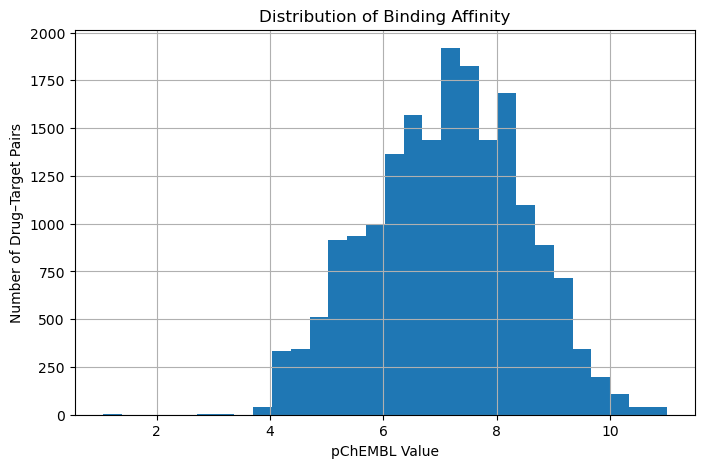

In [58]:
multi_target_aggregated["pchembl_value"].hist(
    bins=30,
    figsize=(8, 5)
)

import matplotlib.pyplot as plt

plt.xlabel("pChEMBL Value")
plt.ylabel("Number of Drug–Target Pairs")
plt.title("Distribution of Binding Affinity")
plt.show()

## 31. Experimental Replicate Distribution

The number of measurements contributing to each drug–target pair is
examined to understand the experimental support for the aggregated
binding-affinity values.

In [59]:
multi_target_aggregated["n_measurements"].describe()

count    18754.000000
mean         1.494028
std          4.831010
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        528.000000
Name: n_measurements, dtype: float64

In [60]:
multi_target_aggregated["n_measurements"].value_counts().sort_index().head(20)

n_measurements
1     15958
2      1705
3       495
4       142
5        77
6        52
7       122
8        14
9        10
10       10
11       16
12        9
13       10
14        9
15       10
16       12
17        8
18        5
19        3
20       12
Name: count, dtype: int64

## 32. Add Protein Target Information

ChEMBL target identifiers are linked with their corresponding protein
names to improve biological interpretability.

The identifiers are retained because they provide stable references to
the ChEMBL target records.

In [61]:
target_metadata = selected_targets[
    [
        "target_chembl_id",
        "pref_name",
        "organism"
    ]
].drop_duplicates()

multi_target_aggregated = multi_target_aggregated.merge(
    target_metadata,
    on="target_chembl_id",
    how="left"
)

multi_target_aggregated.head()

,molecule_chembl_id,target_chembl_id,pchembl_value,n_measurements,activity_types,pref_name,organism
0,CHEMBL10,CHEMBL1862,5.495,2,Kd,Tyrosine-protein kinase ABL1,Homo sapiens
1,CHEMBL10,CHEMBL203,5.770,23,Kd,Epidermal growth factor receptor,Homo sapiens
2,CHEMBL1000,CHEMBL231,7.500,11,Ki,Histamine H1 receptor,Homo sapiens
3,CHEMBL100075,CHEMBL205,8.150,1,Ki,Carbonic anhydrase 2,Homo sapiens
4,CHEMBL100109,CHEMBL204,9.620,1,Ki,Prothrombin,Homo sapiens


## 33. Final Dataset Quality Check

The processed dataset is checked for missing identifiers, missing
binding-affinity values, and duplicate drug–target combinations before
being saved.

Only complete drug–target observations are retained for downstream
feature engineering.

In [62]:
print("Missing drug IDs:",
      multi_target_aggregated["molecule_chembl_id"].isna().sum())

print("Missing target IDs:",
      multi_target_aggregated["target_chembl_id"].isna().sum())

print("Missing pChEMBL values:",
      multi_target_aggregated["pchembl_value"].isna().sum())

print(
    "Duplicate drug-target pairs:",
    multi_target_aggregated.duplicated(
        ["molecule_chembl_id", "target_chembl_id"]
    ).sum()
)

Missing drug IDs: 0
Missing target IDs: 0
Missing pChEMBL values: 0
Duplicate drug-target pairs: 0


## 34. Save Processed Binding-Affinity Dataset

The cleaned and aggregated multi-target binding-affinity dataset is
saved separately from the raw ChEMBL data.

This dataset will serve as the biological interaction layer for the
machine-learning pipeline.

In [64]:
os.makedirs("../data/processed", exist_ok=True)

processed_path = "../data/processed/multi_target_binding_affinity.csv"

multi_target_aggregated.to_csv(
    processed_path,
    index=False
)

print("Processed dataset saved successfully:")
print(processed_path)

Processed dataset saved successfully:
../data/processed/multi_target_binding_affinity.csv
